# Trial eight: a speed pulse (is option C needed?)

Trial six showed that fish faster than about 1.6 BL/s collide and lose order at 8 decisions per second. Is that damage **temporary** (the group recovers when it slows down) or **permanent** (it breaks apart)? We measure how bad option A (the Puckett model as it is) is; option C is not programmed, because with a fixed step length the group behaves the same at any speed (trial six). The story and the decision are in [chapter 8 of the README](../README.md#chapter-8-trial-eight-a-speed-pulse-is-option-c-needed).

- **Part A:** 60 s at 1 BL/s, a pulse at 2.6 or 5 BL/s for 2, 10, 30 or 60 s, then 60 s at 1 BL/s. How long does the group need to recover?
- **Part B:** in one long run, the speed goes up from 0.2 to 5 BL/s and back down. Does the group remember having been fast?

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (it contains study_code/) and let Python import the shared study code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
sys.path.insert(0, str(CHECKS_FOLDER / "study_code"))

import study_tools
from study_tools import (
    PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR, DIRECTION_NAMES,
    average, build_model, change_settings, fraction_of_moments, has_collision, load_results,
    measure_moment, run_and_measure_last_third, smallest, translate,
)

# Where this trial keeps its saved results and its README figure.
DATA_FOLDER = CHECKS_FOLDER / "trial_eight_speed_pulse" / "data"
FIGURE_FOLDER = CHECKS_FOLDER / "trial_eight_speed_pulse" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
import time

## Settings

The model is Puckett's (A4) with the group starting together. The recovery definition and the decision rule were fixed before running:

- a **good moment**: at least 19 of the 20 fish in the largest group, polarization of at least 0.9, and no collision;
- the group **recovered** when there are 5 s (40 decisions) of good moments in a row, all inside the 60 s of recovery (so 55 s is the longest possible recovery time);
- the group was **ready** if the last 5 s of the warm-up were all good moments;
- the rule counts all 10 seeds of each combination, also the seeds that were not ready.

In [2]:
SEEDS = list(range(10))
PULSE_SETTINGS = change_settings(PUCKETT_SETTINGS, "A4, compact start", {"initial_spread": 0.25})

# A good moment and a recovery.
GOOD_LARGEST_FRACTION = 0.95
GOOD_POLARIZATION = 0.9
GOOD_SECONDS = 5

# Part A: warm-up, pulse and recovery (speeds in BL/s, times in s).
NORMAL_SPEED = 1.0
WARM_UP_SECONDS = 60
RECOVERY_SECONDS = 60
PULSE_SPEEDS = [2.6, 5.0]
PULSE_DURATIONS = [2, 10, 30, 60]
CONTROL_SPEED, CONTROL_SECONDS = 1.0, 0     # the control has no pulse
LONG_RECOVERY_SECONDS = 300                 # extra: a longer recovery for the runs that did not recover

# The decision rule.
FAST_RECOVERY_SECONDS = 10    # "A is enough": at least 9 of 10 seeds recover within 10 s, in every combination
SEEDS_NEEDED = 9
BROKEN_SEEDS = 2              # "A has a real problem": 2 or more seeds do not recover within 60 s somewhere

# Part B: one long run, speed up and back down; 30 s per speed, the last third is measured.
RAMP_SPEEDS = [0.2, 0.5, 1.0, 1.6, 2.0, 2.6, 3.5, 5.0]
RAMP_WARM_UP_SPEED = 0.2
SECONDS_PER_SPEED = 30
TRIAL_SIX_LIMIT = 1.6         # BL/s: step length 0.2 BL, the limit found in trial six

DT = PULSE_SETTINGS["dt"]
for key in ["n_fish", "repulsion_radius", "orientation_radius", "attraction_radius", "fov_degrees",
            "turn_per_decision", "noise_per_decision", "arena", "dt", "initial_spread"]:
    print(f"{key:20s} {PULSE_SETTINGS[key]}")

n_fish               20
repulsion_radius     0.5
orientation_radius   3.0
attraction_radius    5.5
fov_degrees          270.0
turn_per_decision    1.75
noise_per_decision   0.01
arena                28.0
dt                   0.125
initial_spread       0.25


## Helper functions

Seconds to decisions, and changing the speed of every fish between two steps.

In [3]:
def seconds_to_decisions(seconds):
    """Number of decisions in `seconds` (8 per second when dt = 0.125 s)."""
    return round(seconds / DT)


def set_speed(model, speed):
    """Give every fish the same new speed.

    This works because, with speed_gain = 0, each fish reads fish.speed at every decision
    (new position = position + direction * speed * dt), while model.dt stays 0.125 s.
    So from the next decision on, the step length is speed * 0.125 BL.
    """
    for fish in model.agents:
        fish.speed = speed
        fish.base_speed = speed
        fish.next_speed = speed


GOOD_STREAK = seconds_to_decisions(GOOD_SECONDS)   # 40 decisions

Is a moment good? When did the group recover? Was it ready at the start of the pulse?

In [4]:
def is_good_moment(moment):
    """True when the group is together, ordered and without any collision."""
    together = moment["largest_fraction"] >= GOOD_LARGEST_FRACTION
    ordered = moment["polarization"] >= GOOD_POLARIZATION
    no_collision = moment["closest_pair"] >= study_tools.COLLISION_DISTANCE
    return together and ordered and no_collision


def all_good(moments):
    """True when every moment in the list is good."""
    for moment in moments:
        if not is_good_moment(moment):
            return False
    return True


def recovery_time(moments_after_pulse):
    """Seconds from the end of the pulse until GOOD_STREAK good moments in a row start (None = never).

    moments_after_pulse[i] is measured after decision i + 1 of the recovery, and that
    decision starts i * dt seconds after the end of the pulse.
    """
    for start in range(len(moments_after_pulse) - GOOD_STREAK + 1):
        if all_good(moments_after_pulse[start:start + GOOD_STREAK]):
            return start * DT
    return None


def ready_at_pulse_start(warm_up_moments):
    """True when the last GOOD_STREAK decisions of the warm-up are all good."""
    return all_good(warm_up_moments[-GOOD_STREAK:])

One run with a pulse: warm-up, pulse and recovery, measured at every decision.

In [5]:
def run_phase(model, speed, n_decisions):
    """Swim n_decisions decisions at `speed` and measure the group after every decision."""
    set_speed(model, speed)
    moments = []
    for _ in range(n_decisions):
        model.step()
        moments.append(measure_moment(model))
    return moments


def timeseries_rows(seed, pulse_speed, pulse_seconds, phases):
    """One row per decision: the time since the start of the run and the measurements."""
    rows = []
    decision = 0
    for phase_name, moments in phases:
        for moment in moments:
            decision += 1
            rows.append({"seed": seed, "pulse_speed": pulse_speed, "pulse_seconds": pulse_seconds,
                         "time_s": decision * DT, "phase": phase_name,
                         "polarization": moment["polarization"], "rotation": moment["rotation"],
                         "largest_fraction": moment["largest_fraction"], "closest_pair": moment["closest_pair"],
                         "nnd": moment["nnd"], "collision": has_collision(moment)})
    return rows


def summary_row(seed, pulse_speed, pulse_seconds, warm_up, pulse, recovery):
    """One row per run: was the group ready, did it recover, how bad was the pulse, how did it end."""
    time_to_recover = recovery_time(recovery)
    row = {"seed": seed, "pulse_speed": pulse_speed, "pulse_seconds": pulse_seconds,
           "ready_at_pulse_start": ready_at_pulse_start(warm_up),
           "recovery_time_s": np.nan if time_to_recover is None else time_to_recover,
           "recovered_within_10_s": time_to_recover is not None and time_to_recover <= FAST_RECOVERY_SECONDS,
           "recovered_within_60_s": time_to_recover is not None}

    # How bad was the pulse? (The control has no pulse, so these stay empty.)
    row["pulse_collision_fraction"] = np.nan
    row["pulse_min_pair_distance"] = np.nan
    row["pulse_min_largest_fraction"] = np.nan
    row["pulse_mean_polarization"] = np.nan
    if len(pulse) > 0:
        row["pulse_collision_fraction"] = fraction_of_moments(pulse, has_collision)
        row["pulse_min_pair_distance"] = smallest(pulse, "closest_pair")
        row["pulse_min_largest_fraction"] = smallest(pulse, "largest_fraction")
        row["pulse_mean_polarization"] = average(pulse, "polarization")

    # The last 5 s of the recovery: why did a run not recover (split group, low order or collisions)?
    last_moments = recovery[-GOOD_STREAK:]
    row["end_largest_fraction"] = average(last_moments, "largest_fraction")
    row["end_polarization"] = average(last_moments, "polarization")
    row["end_collision_fraction"] = fraction_of_moments(last_moments, has_collision)
    return row


def run_pulse(seed, pulse_speed, pulse_seconds, recovery_seconds=RECOVERY_SECONDS):
    """Warm-up, pulse and recovery in one simulation. Returns (rows per decision, summary row, recovery)."""
    start_time = time.perf_counter()
    model = build_model(PULSE_SETTINGS, seed)
    warm_up = run_phase(model, NORMAL_SPEED, seconds_to_decisions(WARM_UP_SECONDS))
    pulse = run_phase(model, pulse_speed, seconds_to_decisions(pulse_seconds))
    recovery = run_phase(model, NORMAL_SPEED, seconds_to_decisions(recovery_seconds))

    rows = timeseries_rows(seed, pulse_speed, pulse_seconds, [("warm_up", warm_up), ("pulse", pulse), ("recovery", recovery)])
    summary = summary_row(seed, pulse_speed, pulse_seconds, warm_up, pulse, recovery)
    summary["n_decisions"] = len(rows)
    summary["runtime_s"] = time.perf_counter() - start_time
    return rows, summary, recovery


def run_pulse_configurations(configurations, timeseries_path, summary_path):
    """Run every (pulse_speed, pulse_seconds) with every seed, or load the saved files."""
    if timeseries_path.exists() and summary_path.exists() and not study_tools.RERUN:
        print(f"Loaded saved results from {summary_path.name} and {timeseries_path.name}.")
        return load_results(timeseries_path), load_results(summary_path)
    all_rows = []
    summaries = []
    for pulse_speed, pulse_seconds in configurations:
        for seed in SEEDS:
            rows, summary, _ = run_pulse(seed, pulse_speed, pulse_seconds)
            all_rows.extend(rows)
            summaries.append(summary)
        print(f"{pulse_speed} BL/s for {pulse_seconds} s done", flush=True)
    pd.DataFrame(all_rows).to_csv(timeseries_path, index=False)
    pd.DataFrame(summaries).to_csv(summary_path, index=False)
    return load_results(timeseries_path), load_results(summary_path)

Part B: one long run in which the speed goes up and back down.

In [6]:
def run_ramp(seed):
    """Warm-up at 0.2 BL/s, then the speed goes up through RAMP_SPEEDS and back down."""
    model = build_model(PULSE_SETTINGS, seed)
    set_speed(model, RAMP_WARM_UP_SPEED)
    for _ in range(seconds_to_decisions(WARM_UP_SECONDS)):
        model.step()

    rows = []
    for direction, speeds in [("subiendo", RAMP_SPEEDS), ("bajando", list(reversed(RAMP_SPEEDS)))]:
        for speed in speeds:
            set_speed(model, speed)
            moments = run_and_measure_last_third(model, seconds_to_decisions(SECONDS_PER_SPEED))
            rows.append({"seed": seed, "direction": direction, "speed": speed,
                         "polarization": average(moments, "polarization"),
                         "largest_fraction": average(moments, "largest_fraction"),
                         "collision_fraction": fraction_of_moments(moments, has_collision),
                         "min_pair_distance": smallest(moments, "closest_pair")})
    return rows

## Run or load

First the control (no pulse; its recovery is measured from the end of the warm-up). If fewer than 9 of 10 control seeds recover within 10 s, the criterion is too strict and we stop.

In [7]:
control_timeseries, control_summary = run_pulse_configurations(
    [(CONTROL_SPEED, CONTROL_SECONDS)], DATA_FOLDER / "control_timeseries.csv.gz", DATA_FOLDER / "control_summary.csv")
control_recovered = int(control_summary["recovered_within_10_s"].sum())
print(f"Control: {int(control_summary['ready_at_pulse_start'].sum())} of 10 seeds ready, "
      f"{control_recovered} of 10 recover within {FAST_RECOVERY_SECONDS} s.")
if control_recovered < SEEDS_NEEDED:
    raise RuntimeError("STOP: the recovery criterion may be too strict. Ask the group before going on.")

Loaded saved results from control_summary.csv and control_timeseries.csv.gz.
Control: 8 of 10 seeds ready, 10 of 10 recover within 10 s.


The pulses: 2 speeds × 4 durations × 10 seeds = 80 runs.

In [8]:
PULSE_CONFIGURATIONS = []
for pulse_speed in PULSE_SPEEDS:
    for pulse_seconds in PULSE_DURATIONS:
        PULSE_CONFIGURATIONS.append((pulse_speed, pulse_seconds))

pulse_timeseries, pulse_summary = run_pulse_configurations(
    PULSE_CONFIGURATIONS, DATA_FOLDER / "pulse_timeseries.csv.gz", DATA_FOLDER / "pulse_summary.csv")
all_summaries = pd.concat([control_summary, pulse_summary], ignore_index=True)
all_timeseries = pd.concat([control_timeseries, pulse_timeseries], ignore_index=True)
print("Runs:", len(all_summaries))

Loaded saved results from pulse_summary.csv and pulse_timeseries.csv.gz.
Runs: 90


Extra: the runs that did not recover within 60 s, again with a 300 s recovery. With the same seed the first 60 s are identical, so we only see whether the group recovers later. This does not change the decision, which uses 60 s.

In [9]:
long_path = DATA_FOLDER / "extra_long_recovery.csv"
if long_path.exists() and not study_tools.RERUN:
    print("Loaded saved results from", long_path.name)
else:
    first_60_s = seconds_to_decisions(RECOVERY_SECONDS)
    long_rows = []
    never_recovered = all_summaries[~all_summaries["recovered_within_60_s"]]
    for index in range(len(never_recovered)):
        run = never_recovered.iloc[index]
        _, _, recovery = run_pulse(int(run["seed"]), run["pulse_speed"], run["pulse_seconds"], LONG_RECOVERY_SECONDS)
        assert recovery_time(recovery[:first_60_s]) is None   # the same answer as the original run
        time_to_recover = recovery_time(recovery)
        long_rows.append({"pulse_speed": run["pulse_speed"], "pulse_seconds": run["pulse_seconds"],
                          "seed": int(run["seed"]),
                          "recovery_time_300_s": np.nan if time_to_recover is None else time_to_recover,
                          "fish_in_largest_group_at_60_s": round(20 * recovery[first_60_s - 1]["largest_fraction"]),
                          "fish_in_largest_group_at_300_s": round(20 * recovery[-1]["largest_fraction"])})
    pd.DataFrame(long_rows).to_csv(long_path, index=False)
long_recovery_results = load_results(long_path)

Loaded saved results from extra_long_recovery.csv


Part B: the ramp with 10 seeds.

In [10]:
ramp_path = DATA_FOLDER / "ramp.csv"
if ramp_path.exists() and not study_tools.RERUN:
    print("Loaded saved results from", ramp_path.name)
else:
    ramp_rows = []
    for seed in SEEDS:
        ramp_rows.extend(run_ramp(seed))
    pd.DataFrame(ramp_rows).to_csv(ramp_path, index=False)
ramp = load_results(ramp_path)
ramp["direction"] = translate(ramp["direction"], DIRECTION_NAMES)

Loaded saved results from ramp.csv


## Results tables

**The decision table.** For each combination: seeds ready at the start, recovered within 10 s and within 60 s, the median recovery time (a run that never recovered counts as the slowest) and the time with a collision during the pulse.

In [11]:
def runs_of(summaries, pulse_speed, pulse_seconds):
    """The summary rows of one combination."""
    return summaries[(summaries["pulse_speed"] == pulse_speed) & (summaries["pulse_seconds"] == pulse_seconds)]


def median_recovery_text(runs):
    """Median recovery time over all seeds; a run that never recovered counts as the slowest."""
    times = []
    for value in runs["recovery_time_s"]:
        if np.isnan(value):
            times.append(np.inf)
        else:
            times.append(value)
    median = np.median(times)
    if np.isinf(median):
        return "> 55 s"
    return f"{median:.1f} s"


rows = []
for pulse_speed, pulse_seconds in [(CONTROL_SPEED, CONTROL_SECONDS)] + PULSE_CONFIGURATIONS:
    runs = runs_of(all_summaries, pulse_speed, pulse_seconds)
    name = "control (no pulse)"
    collisions = "-"
    if pulse_seconds > 0:
        name = f"{pulse_speed} BL/s, {pulse_seconds} s"
        collisions = f"{100 * runs['pulse_collision_fraction'].mean():.0f} %"
    rows.append({"combination": name,
                 "ready at start": f"{int(runs['ready_at_pulse_start'].sum())}/{len(runs)}",
                 "recovered within 10 s": f"{int(runs['recovered_within_10_s'].sum())}/{len(runs)}",
                 "recovered within 60 s": f"{int(runs['recovered_within_60_s'].sum())}/{len(runs)}",
                 "median recovery time": median_recovery_text(runs),
                 "time with a collision in the pulse": collisions})
pd.DataFrame(rows)

,combination,ready at start,recovered within 10 s,recovered within 60 s,median recovery time,time with a collision in the pulse
0,control (no pulse),8/10,10/10,10/10,0.0 s,-
1,"2.6 BL/s, 2 s",8/10,10/10,10/10,3.6 s,10 %
2,"2.6 BL/s, 10 s",8/10,8/10,10/10,2.2 s,17 %
3,"2.6 BL/s, 30 s",8/10,8/10,9/10,1.5 s,17 %
4,"2.6 BL/s, 60 s",8/10,9/10,10/10,7.2 s,16 %
5,"5.0 BL/s, 2 s",8/10,8/10,10/10,5.8 s,25 %
6,"5.0 BL/s, 10 s",8/10,5/10,9/10,9.7 s,38 %
7,"5.0 BL/s, 30 s",8/10,3/10,9/10,18.4 s,38 %
8,"5.0 BL/s, 60 s",8/10,3/10,6/10,28.7 s,38 %


**The decision rule, applied literally.**

In [12]:
every_combination_fast = True
some_combination_broken = False
for pulse_speed, pulse_seconds in PULSE_CONFIGURATIONS:
    runs = runs_of(all_summaries, pulse_speed, pulse_seconds)
    recovered_fast = int(runs["recovered_within_10_s"].sum())
    never_recovered = int((~runs["recovered_within_60_s"]).sum())
    if recovered_fast < SEEDS_NEEDED:
        every_combination_fast = False
        print(f"{pulse_speed} BL/s, {pulse_seconds} s: only {recovered_fast} of 10 seeds recover within 10 s.")
    if never_recovered >= BROKEN_SEEDS:
        some_combination_broken = True
        print(f"{pulse_speed} BL/s, {pulse_seconds} s: {never_recovered} seeds do not recover within 60 s.")

if every_combination_fast:
    print("Decision: A is enough.")
elif some_combination_broken:
    print("Decision: A has a real problem.")
else:
    print("Decision: grey zone.")

2.6 BL/s, 10 s: only 8 of 10 seeds recover within 10 s.
2.6 BL/s, 30 s: only 8 of 10 seeds recover within 10 s.
5.0 BL/s, 2 s: only 8 of 10 seeds recover within 10 s.
5.0 BL/s, 10 s: only 5 of 10 seeds recover within 10 s.
5.0 BL/s, 30 s: only 3 of 10 seeds recover within 10 s.
5.0 BL/s, 60 s: only 3 of 10 seeds recover within 10 s.
5.0 BL/s, 60 s: 4 seeds do not recover within 60 s.
Decision: A has a real problem.


How bad was each pulse? Means of the 10 seeds during the pulse.

In [13]:
pulse_summary.groupby(["pulse_speed", "pulse_seconds"], sort=False)[
    ["pulse_collision_fraction", "pulse_min_pair_distance", "pulse_min_largest_fraction", "pulse_mean_polarization"]].mean()

pulse_collision_fraction  pulse_min_pair_distance  pulse_min_largest_fraction  pulse_mean_polarization
pulse_speed pulse_seconds                                                                                                        
2.6         2                                 0.100                    0.414                       0.995                    0.937
            10                                0.170                    0.048                       0.985                    0.898
            30                                0.166                    0.027                       0.970                    0.885
            60                                0.158                    0.022                       0.960                    0.887
5.0         2                                 0.250                    0.135                       0.995                    0.844
            10                                0.385                    0.044                       0.960                    0.746
            30                                0.376                    0.022                       0.905                    0.707
            60                                0.381                    0.017                       0.865                    0.688

Seeds that were not ready at the start of the pulse (kept, shown here apart).

In [14]:
not_ready = all_summaries[~all_summaries["ready_at_pulse_start"]]
not_ready[["pulse_speed", "pulse_seconds", "seed", "recovery_time_s", "recovered_within_10_s", "recovered_within_60_s"]]

,pulse_speed,pulse_seconds,seed,recovery_time_s,recovered_within_10_s,recovered_within_60_s
0,1.0,0,0,1.375,True,True
1,1.0,0,1,0.000,True,True
10,2.6,2,0,0.000,True,True
11,2.6,2,1,4.250,True,True
20,2.6,10,0,1.750,True,True
21,2.6,10,1,2.625,True,True
30,2.6,30,0,NaN,False,False
31,2.6,30,1,2.500,True,True
40,2.6,60,0,6.875,True,True
41,2.6,60,1,0.000,True,True


Why did some runs not recover? The state of the group in the last 5 s of the recovery (means of the 10 seeds), and the longer recovery of the extra test.

In [15]:
all_summaries.groupby(["pulse_speed", "pulse_seconds"], sort=False)[
    ["end_largest_fraction", "end_polarization", "end_collision_fraction"]].mean()

end_largest_fraction  end_polarization  end_collision_fraction
pulse_speed pulse_seconds                                                                
1.0         0                             0.995             0.991                   0.000
2.6         2                             0.995             0.981                   0.003
            10                            0.995             0.958                   0.003
            30                            0.990             0.951                   0.000
            60                            1.000             0.987                   0.000
5.0         2                             1.000             0.970                   0.000
            10                            0.980             0.956                   0.000
            30                            0.989             0.961                   0.000
            60                            0.950             0.892                   0.000

In [16]:
long_recovery_results

,pulse_speed,pulse_seconds,seed,recovery_time_300_s,fish_in_largest_group_at_60_s,fish_in_largest_group_at_300_s
0,2.6,30,0,155.750,18,20
1,5.0,10,8,75.000,18,20
2,5.0,30,5,69.625,20,20
3,5.0,60,0,111.000,18,20
4,5.0,60,1,167.125,17,20
5,5.0,60,3,75.875,18,20
6,5.0,60,4,154.375,18,20


**Part B.** Going up and going down, side by side (means of the 10 seeds over the last third of each speed).

In [17]:
RAMP_COLUMNS = ["polarization", "largest_fraction", "collision_fraction", "min_pair_distance"]
ramp_summary = ramp.groupby(["direction", "speed"], sort=False)[RAMP_COLUMNS].agg(["mean", "sem"])
side_by_side = pd.DataFrame(index=RAMP_SPEEDS)
side_by_side.index.name = "speed (BL/s)"
for column in ["polarization", "largest_fraction", "collision_fraction"]:
    for direction in ["going up", "going down"]:
        side_by_side[f"{column}, {direction}"] = ramp_summary.loc[direction][(column, "mean")].reindex(RAMP_SPEEDS).values
side_by_side

,"polarization, going up","polarization, going down","largest_fraction, going up","largest_fraction, going down","collision_fraction, going up","collision_fraction, going down"
speed (BL/s),,,,,,
0.2,0.990,0.999,1.000,1.000,0.000,0.000
0.5,0.989,0.999,1.000,1.000,0.000,0.000
1.0,0.986,0.973,1.000,1.000,0.000,0.000
1.6,0.964,0.945,0.995,1.000,0.016,0.033
2.0,0.921,0.946,0.990,0.997,0.076,0.051
2.6,0.887,0.884,0.983,0.977,0.165,0.144
3.5,0.824,0.756,0.986,0.951,0.274,0.312
5.0,0.694,0.689,0.960,0.961,0.375,0.410


## Figures

**The README figure: the recovery time of every run.** Lines at 10 s and 60 s; triangles: runs that did not recover within 60 s.

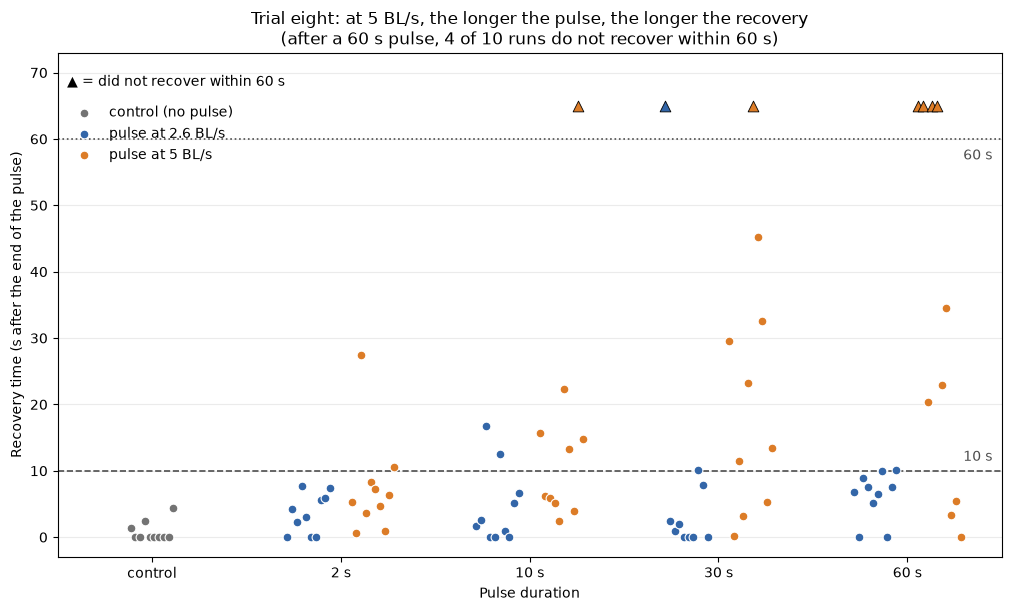

In [18]:
NEVER_HEIGHT = 65    # where the runs that never recovered are drawn
ALL_DURATIONS = [CONTROL_SECONDS] + PULSE_DURATIONS


def recovery_points(runs, center):
    """x positions (slightly spread, so the dots do not hide each other) and recovery times."""
    recovered_x, recovered_y, never_x = [], [], []
    for index in range(len(runs)):
        x = center + (index - 4.5) * 0.025
        value = runs["recovery_time_s"].iloc[index]
        if np.isnan(value):
            never_x.append(x)
        else:
            recovered_x.append(x)
            recovered_y.append(value)
    return recovered_x, recovered_y, never_x


fig, axis = plt.subplots(figsize=(10, 6), constrained_layout=True)
groups = [(CONTROL_SPEED, [CONTROL_SECONDS], "0.45", 0.0, "control (no pulse)"),
          (2.6, PULSE_DURATIONS, A0_COLOR, -0.17, "pulse at 2.6 BL/s"),
          (5.0, PULSE_DURATIONS, PUCKETT_COLOR, 0.17, "pulse at 5 BL/s")]
for pulse_speed, durations, color, offset, label in groups:
    for pulse_seconds in durations:
        runs = runs_of(all_summaries, pulse_speed, pulse_seconds)
        recovered_x, recovered_y, never_x = recovery_points(runs, ALL_DURATIONS.index(pulse_seconds) + offset)
        axis.scatter(recovered_x, recovered_y, color=color, s=40, edgecolor="white", linewidth=0.8, label=label, zorder=3)
        label = None    # one legend entry per group
        if len(never_x) > 0:
            axis.scatter(never_x, [NEVER_HEIGHT] * len(never_x), color=color, marker="^", s=60,
                         edgecolor="black", linewidth=0.6, zorder=3)
axis.axhline(FAST_RECOVERY_SECONDS, color="0.3", linestyle="--", linewidth=1.2)
axis.axhline(RECOVERY_SECONDS, color="0.3", linestyle=":", linewidth=1.2)
axis.text(4.45, FAST_RECOVERY_SECONDS + 1, "10 s", ha="right", va="bottom", color="0.3")
axis.text(4.45, RECOVERY_SECONDS - 1.5, "60 s", ha="right", va="top", color="0.3")
axis.text(-0.45, NEVER_HEIGHT + 2.5, "▲ = did not recover within 60 s", ha="left", va="bottom")
axis.set_xticks(range(len(ALL_DURATIONS)))
axis.set_xticklabels(["control", "2 s", "10 s", "30 s", "60 s"])
axis.set_xlim(-0.5, 4.5)
axis.set_ylim(-3, NEVER_HEIGHT + 8)
axis.set_xlabel("Pulse duration")
axis.set_ylabel("Recovery time (s after the end of the pulse)")
axis.grid(alpha=0.25, axis="y")
axis.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92))
axis.set_title("Trial eight: at 5 BL/s, the longer the pulse, the longer the recovery\n(after a 60 s pulse, 4 of 10 runs do not recover within 60 s)")
fig.savefig(FIGURE_FOLDER / "pulse_recovery.png", dpi=150)
plt.show()

During and after the pulse: one row per pulse duration. Grey band = the pulse; thin lines = single seeds; thick line = mean; dotted lines = the thresholds of a good moment.

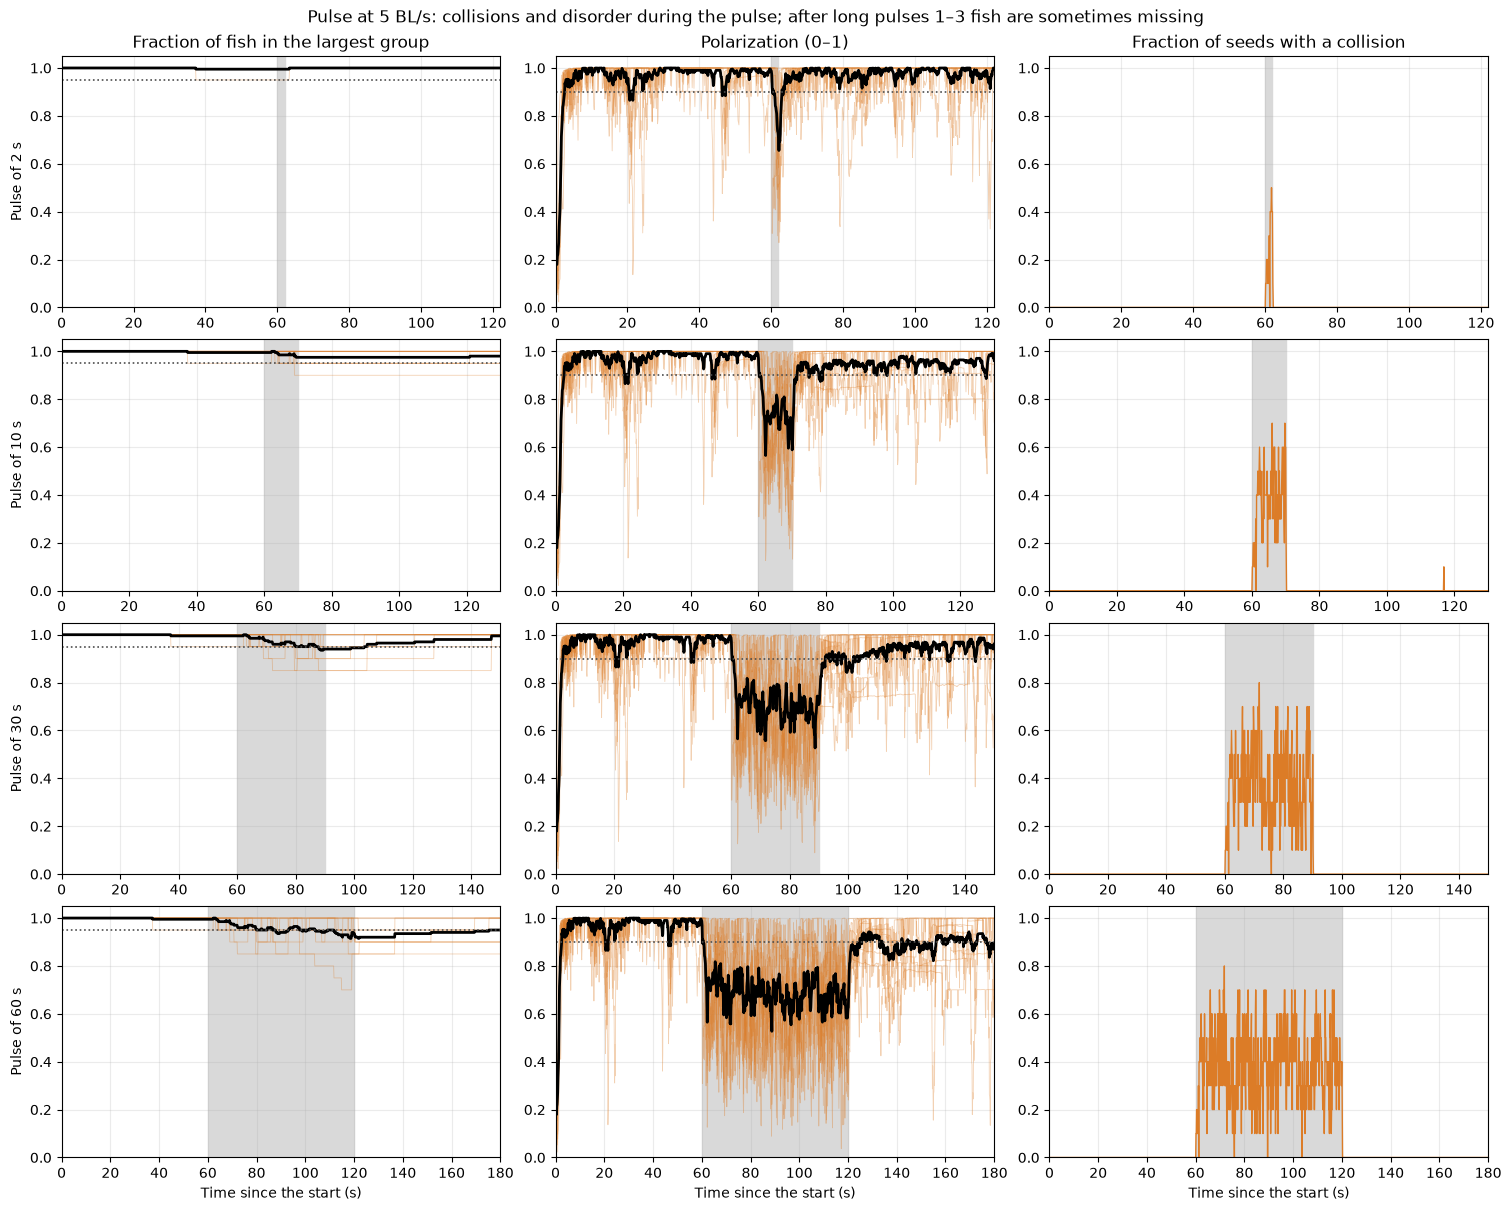

In [19]:
def plot_pulse_figure(pulse_speed, color, title):
    """Largest group, polarization and collisions against time, one row per pulse duration."""
    fig, axes = plt.subplots(len(PULSE_DURATIONS), 3, figsize=(15, 12), constrained_layout=True)
    for row_index in range(len(PULSE_DURATIONS)):
        pulse_seconds = PULSE_DURATIONS[row_index]
        runs = all_timeseries[(all_timeseries["pulse_speed"] == pulse_speed) & (all_timeseries["pulse_seconds"] == pulse_seconds)]
        mean_over_seeds = runs.groupby("time_s")[["largest_fraction", "polarization", "collision"]].mean()
        end_time = WARM_UP_SECONDS + pulse_seconds + RECOVERY_SECONDS
        for column_index in range(3):
            axes[row_index, column_index].axvspan(WARM_UP_SECONDS, WARM_UP_SECONDS + pulse_seconds, color="0.85", zorder=0)
            axes[row_index, column_index].set_xlim(0, end_time)
            axes[row_index, column_index].set_ylim(0, 1.05)
            axes[row_index, column_index].grid(alpha=0.25)
        for column_index, column, threshold in [(0, "largest_fraction", GOOD_LARGEST_FRACTION),
                                                (1, "polarization", GOOD_POLARIZATION)]:
            axis = axes[row_index, column_index]
            for seed in SEEDS:
                one_seed = runs[runs["seed"] == seed]
                axis.plot(one_seed["time_s"], one_seed[column], color=color, linewidth=0.6, alpha=0.35)
            axis.plot(mean_over_seeds.index, mean_over_seeds[column], color="black", linewidth=2)
            axis.axhline(threshold, color="0.3", linestyle=":", linewidth=1.2)
        axes[row_index, 2].plot(mean_over_seeds.index, mean_over_seeds["collision"], color=color, linewidth=1)
        axes[row_index, 0].set_ylabel(f"Pulse of {pulse_seconds} s")
    axes[0, 0].set_title("Fraction of fish in the largest group")
    axes[0, 1].set_title("Polarization (0–1)")
    axes[0, 2].set_title("Fraction of seeds with a collision")
    for column_index in range(3):
        axes[-1, column_index].set_xlabel("Time since the start (s)")
    fig.suptitle(title)
    plt.show()


plot_pulse_figure(5.0, PUCKETT_COLOR, "Pulse at 5 BL/s: collisions and disorder during the pulse; after long pulses 1–3 fish are sometimes missing")

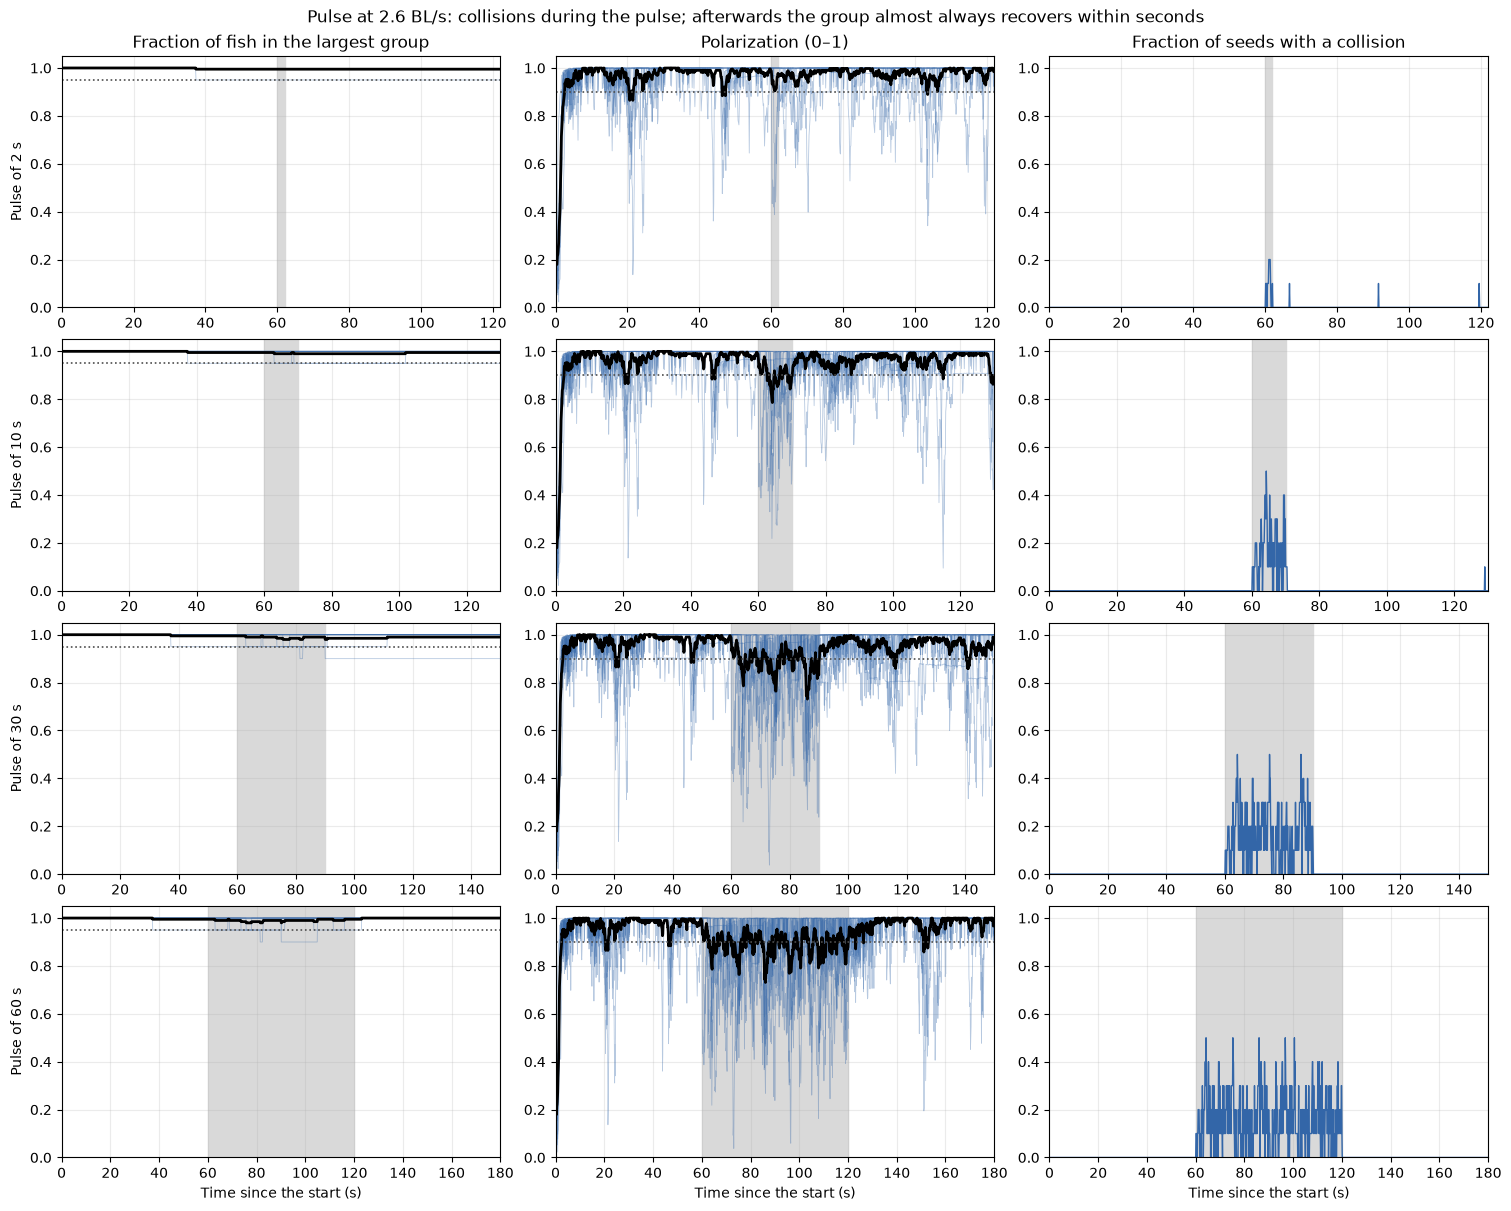

In [20]:
plot_pulse_figure(2.6, A0_COLOR, "Pulse at 2.6 BL/s: collisions during the pulse; afterwards the group almost always recovers within seconds")

Part B: solid line = going up, dashed line = going down (mean ± standard error). Dotted line: 1.6 BL/s, the limit of trial six.

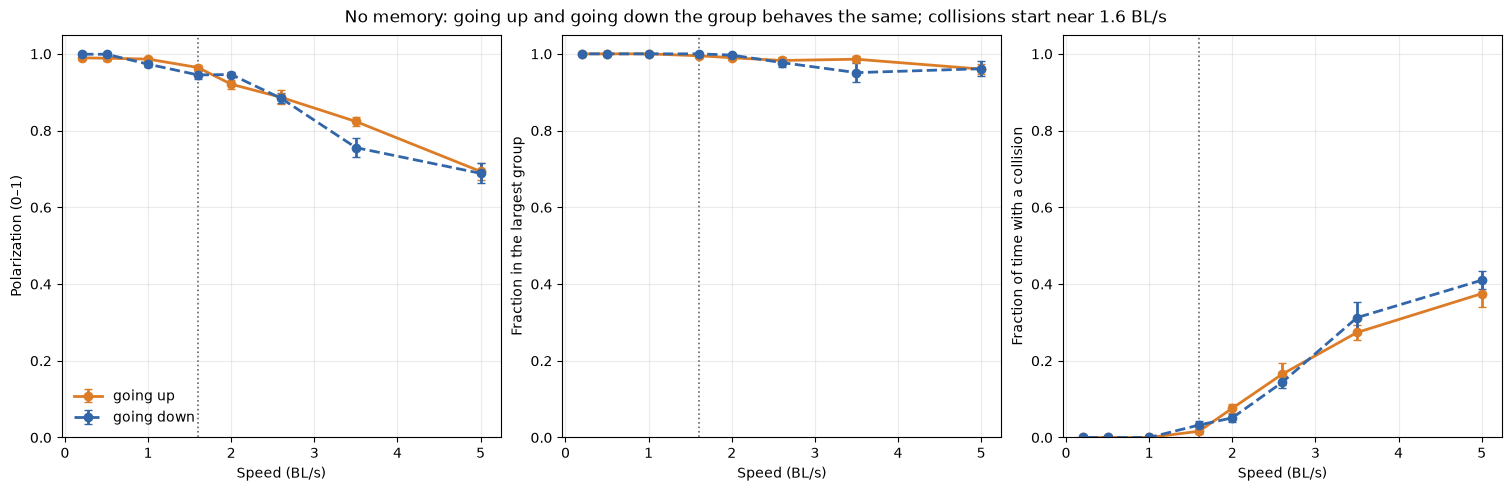

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
panels = [("polarization", "Polarization (0–1)"), ("largest_fraction", "Fraction in the largest group"),
          ("collision_fraction", "Fraction of time with a collision")]
for axis, (column, axis_label) in zip(axes, panels):
    for direction, line_style, color in [("going up", "-", PUCKETT_COLOR), ("going down", "--", A0_COLOR)]:
        rows = ramp_summary.loc[direction]
        axis.errorbar(rows.index, rows[(column, "mean")], yerr=rows[(column, "sem")], color=color,
                      linestyle=line_style, marker="o", markersize=6, linewidth=2, capsize=3, label=direction)
    axis.axvline(TRIAL_SIX_LIMIT, color="0.4", linestyle=":", linewidth=1.2)
    axis.set_xlabel("Speed (BL/s)")
    axis.set_ylabel(axis_label)
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.25)
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("No memory: going up and going down the group behaves the same; collisions start near 1.6 BL/s")
plt.show()

## Conclusion

- **Decision by the rule fixed before running: A has a real problem.** After 60 s at 5 BL/s, 4 of 10 seeds do not recover within 60 s (the rule allows at most 1).
- **The damage is temporary but sometimes slow.** The runs that fail are not broken groups: 1 to 3 fish are missing. With a 300 s recovery, all 7 recover (70 to 167 s after the pulse). There is no memory with speed.
- **During the pulse the model is physically wrong:** at 5 BL/s some pair collides in 25–38 % of the decisions and polarization falls to about 0.7. At 2.6 BL/s the group almost always recovers within 10 s.